# ORIONet-Classifier: Oriented Patch Classification Framework for DIOR-R Benchmark

### Track 2: Transformed Single-Object Aerial Patch Classification
Transforms DIOR-R object-level aerial imagery into independent single-object image patches using OpenCV Rotated Affine Transformation and trains a novel classifier integrating **FOEM, RAFM, SCA, and AMSF**.

**Workflow**:
1. **Rotated Object Cropping**: Reads 8-point polygon annotations from DIOR-R and extracts upright object patches via affine transformation (`cv2.getRotationMatrix2D` + `cv2.warpAffine`), removing background clutter.
2. **Category Organization**: Supports both on-the-fly dynamic cropping and exporting cropped patches into 20 category folders (`/train/airplane/`, `/train/ship/`, etc.).
3. **Novel ORIONet-Classifier Architecture**:
   - **FOEM (Fine-Grained Object Enhancement Module)**: Retains high-frequency edge textures and small-object boundaries in aerial patches.
   - **RAFM (Rotation-Aware Feature Module)**: Uses horizontal ($1\times 7$), vertical ($7\times 1$), and isotropic ($3\times 3$) directional depthwise kernels with orientation attention gating for rotation-invariant feature learning.
   - **SCA (Spatial Context Aggregation Module)**: Multi-dilation depthwise convolutions ($r \in \{1, 3, 5\}$) with global context pooling.
   - **AMSF (Adaptive Multi-Scale Fusion)**: Dynamically weights multi-scale pyramid features with learnable normalized scale weights ($\sum \alpha_i = 1$).
   - **Classification Head**: Global Average Pooling + LayerNorm + Linear Classifier for the 20 DIOR-R categories.
4. **Training Configuration**: Exactly **50 Epochs**, Automatic Mixed Precision (AMP FP16), AdamW, Cosine Annealing, Label Smoothing, and live `tqdm` progress tracking.


In [1]:
# Cell 1: Environment Setup, Dependencies & Deterministic Reproducibility
import os
import sys
import math
import time
import glob
import random
import yaml
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset

# Deterministic seed for reproducible research
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# Hardware acceleration setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Executing on device: {device}")
if torch.cuda.is_available():
    print(f"Device Name: {torch.cuda.get_device_name(0)}")
    print(f"Allocated VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    print(f"PyTorch Version: {torch.__version__} | CUDA Version: {torch.version.cuda}")


c:\Users\cscpr\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Executing on device: cuda
Device Name: NVIDIA GeForce RTX 4050 Laptop GPU
Allocated VRAM: 6.44 GB
PyTorch Version: 2.14.0+cu130 | CUDA Version: 13.0


In [2]:
# Cell 2: DIOR-R Dataset Configuration & Class Mapping
DATASET_ROOT = 'dataset/YOLODIOR-R'
DATA_YAML_PATH = os.path.join(DATASET_ROOT, 'data.yaml')

with open(DATA_YAML_PATH, 'r') as f:
    data_config = yaml.safe_load(f)

CLASSES = [data_config['names'][i] for i in range(len(data_config['names']))]
NUM_CLASSES = len(CLASSES)
print(f"DIOR-R Dataset loaded with {NUM_CLASSES} classes for classification:")
for i, name in enumerate(CLASSES):
    print(f"  [{i:02d}] {name}")


DIOR-R Dataset loaded with 20 classes for classification:
  [00] airplane
  [01] airport
  [02] baseballfield
  [03] basketballcourt
  [04] bridge
  [05] chimney
  [06] dam
  [07] Expressway-Service-area
  [08] Expressway-toll-station
  [09] golffield
  [10] groundtrackfield
  [11] harbor
  [12] overpass
  [13] ship
  [14] stadium
  [15] storagetank
  [16] tenniscourt
  [17] trainstation
  [18] vehicle
  [19] windmill


In [3]:
# Cell 3: Rotated Object Cropping Engine (Affine Transformation)
# Extracts upright rectangular patches from arbitrarily oriented aerial annotations

def poly_to_rbox(poly_pts):
    """Converts 4 corner polygon points shape (4, 2) to rotated box (cx, cy, w, h, angle_deg)."""
    rect = cv2.minAreaRect(poly_pts.astype(np.float32))
    (cx, cy), (w, h), angle_deg = rect
    if w < h:
        w, h = h, w
        angle_deg += 90.0
    return cx, cy, w, h, angle_deg

def crop_rotated_patch(img, cx, cy, w, h, angle_deg, target_size=(128, 128)):
    """
    Performs affine transformation to crop a rotated bounding box upright.
    Returns: RGB image patch resized to target_size (default 128x128).
    """
    w = max(int(round(w)), 8)
    h = max(int(round(h)), 8)
    
    # 2D Affine rotation matrix centered on object center
    M = cv2.getRotationMatrix2D((cx, cy), angle_deg, 1.0)
    # Translation to center the crop in the output window
    M[0, 2] += (w / 2.0 - cx)
    M[1, 2] += (h / 2.0 - cy)
    
    # Warp image to extract upright patch
    cropped = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    
    # Resize to standardized classification resolution
    if cropped.shape[:2] != target_size:
        cropped = cv2.resize(cropped, target_size, interpolation=cv2.INTER_LINEAR)
        
    return cropped

def export_cropped_dataset(source_root, output_dir='dataset/DIOR_Cropped_Cls', split='val', max_per_class=100, target_size=(128, 128)):
    """
    Utility to export rotated crops into class-specific subfolders on disk:
    output_dir/split/class_name/xxx.jpg
    """
    images_dir = os.path.join(source_root, split, 'images')
    labels_dir = os.path.join(source_root, split, 'labels')
    split_out = os.path.join(output_dir, split)
    
    for cname in CLASSES:
        os.makedirs(os.path.join(split_out, cname), exist_ok=True)
        
    class_counts = {c: 0 for c in range(NUM_CLASSES)}
    label_files = sorted(glob.glob(os.path.join(labels_dir, '*.txt')))
    
    print(f"Exporting sample rotated crops for '{split}' split into: {split_out}...")
    for l_path in label_files:
        base_name = os.path.splitext(os.path.basename(l_path))[0]
        img_path = os.path.join(images_dir, base_name + '.jpg')
        if not os.path.exists(img_path):
            img_path = os.path.join(images_dir, base_name + '.png')
        if not os.path.exists(img_path):
            continue
            
        img = cv2.imread(img_path)
        if img is None:
            continue
        h_orig, w_orig = img.shape[:2]
        
        with open(l_path, 'r') as f:
            for obj_idx, line in enumerate(f):
                parts = line.strip().split()
                if len(parts) >= 9:
                    cid = int(float(parts[0]))
                    if class_counts[cid] >= max_per_class:
                        continue
                        
                    pts = np.array([float(x) for x in parts[1:9]], dtype=np.float32).reshape(4, 2)
                    pts[:, 0] *= w_orig
                    pts[:, 1] *= h_orig
                    
                    cx, cy, w, h, angle_deg = poly_to_rbox(pts)
                    patch = crop_rotated_patch(img, cx, cy, w, h, angle_deg, target_size=target_size)
                    
                    out_filename = f"{base_name}_obj{obj_idx}_{CLASSES[cid]}.jpg"
                    out_file_path = os.path.join(split_out, CLASSES[cid], out_filename)
                    cv2.imwrite(out_file_path, patch)
                    class_counts[cid] += 1
                    
    total_exported = sum(class_counts.values())
    print(f"Successfully exported {total_exported} rotated object patches across {NUM_CLASSES} classes.")
    return split_out

print("Rotated Cropping Engine initialized.")


Rotated Cropping Engine initialized.


In [4]:
# Cell 4: Dynamic On-The-Fly Cropped Classification Dataset
class DIORRCroppedClassificationDataset(Dataset):
    """
    Indexes all individual object annotations across DIOR-R images and crops rotated patches on-the-fly.
    Eliminates disk duplication while supporting extensive real-time augmentations.
    """
    def __init__(self, root_dir, split='train', target_size=(128, 128), max_samples=None, augment=False):
        self.root_dir = root_dir
        self.split = split
        self.target_size = target_size
        self.augment = augment
        self._img_cache = {}
        
        self.images_dir = os.path.join(root_dir, split, 'images')
        self.labels_dir = os.path.join(root_dir, split, 'labels')
        
        label_files = sorted(glob.glob(os.path.join(self.labels_dir, '*.txt')))
        self.samples = [] # List of tuples: (img_path, cx, cy, w, h, angle_deg, class_id)
        
        print(f"Indexing object annotations for '{split}' split...")
        for l_path in label_files:
            if max_samples is not None and len(self.samples) >= max_samples * 2:
                break
            base_name = os.path.splitext(os.path.basename(l_path))[0]
            img_path = os.path.join(self.images_dir, base_name + '.jpg')
            if not os.path.exists(img_path):
                img_path = os.path.join(self.images_dir, base_name + '.png')
            if not os.path.exists(img_path):
                continue
                
            with open(l_path, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) >= 9:
                        cid = int(float(parts[0]))
                        pts = np.array([float(x) for x in parts[1:9]], dtype=np.float32).reshape(4, 2)
                        # DIOR-R images are 800x800
                        pts[:, 0] *= 800.0
                        pts[:, 1] *= 800.0
                        cx, cy, w, h, angle_deg = poly_to_rbox(pts)
                        self.samples.append((img_path, cx, cy, w, h, angle_deg, cid))
                        
        if max_samples is not None:
            random.seed(42)
            random.shuffle(self.samples)
            self.samples = self.samples[:max_samples]
            
        print(f"Indexed {len(self.samples)} rotated object patches for {split} split.")

    def __len__(self):
        return len(self.samples)

    def _load_image(self, img_path):
        if img_path in self._img_cache:
            return self._img_cache[img_path]
        img = cv2.imread(img_path)
        if img is not None:
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            if len(self._img_cache) < 250:
                self._img_cache[img_path] = img_rgb
            return img_rgb
        return None

    def __getitem__(self, idx):
        img_path, cx, cy, w, h, angle_deg, cid = self.samples[idx]
        img_rgb = self._load_image(img_path)
        if img_rgb is None:
            # Fallback black patch if image loading fails
            patch = np.zeros((*self.target_size, 3), dtype=np.uint8)
        else:
            patch = crop_rotated_patch(img_rgb, cx, cy, w, h, angle_deg, target_size=self.target_size)
            
        # Real-time augmentations during training
        if self.augment:
            if random.random() > 0.5:
                patch = cv2.flip(patch, 1) # Horizontal flip
            if random.random() > 0.5:
                patch = cv2.flip(patch, 0) # Vertical flip
            if random.random() > 0.5:
                rot_k = random.choice([1, 2, 3])
                patch = np.rot90(patch, rot_k).copy()
                
        # Normalization
        tensor = torch.from_numpy(patch).permute(2, 0, 1).float() / 255.0
        mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
        tensor = (tensor - mean) / std
        
        return tensor, torch.tensor(cid, dtype=torch.long)


In [5]:
# Cell 5: ORIONet-Classifier Architecture (Inverted Residuals + FOEM + RAFM + SCA + AMSF)
class ConvBNSiLU(nn.Module):
    """Standard Convolution Block with BatchNorm and SiLU."""
    def __init__(self, in_ch, out_ch, k=3, s=1, p=None, g=1):
        super().__init__()
        p = k // 2 if p is None else p
        self.conv = nn.Conv2d(in_ch, out_ch, k, stride=s, padding=p, groups=g, bias=False)
        self.bn = nn.BatchNorm2d(out_ch)
        self.act = nn.SiLU(inplace=True)

    def forward(self, x):
        return self.act(self.bn(self.conv(x)))

class InvertedResidual(nn.Module):
    """Mobile-style inverted bottleneck block."""
    def __init__(self, in_ch, out_ch, stride=1, expand_ratio=2):
        super().__init__()
        self.stride = stride
        hidden_dim = int(round(in_ch * expand_ratio))
        self.use_res_connect = self.stride == 1 and in_ch == out_ch

        layers = []
        if expand_ratio != 1:
            layers.append(ConvBNSiLU(in_ch, hidden_dim, k=1))
        layers.extend([
            ConvBNSiLU(hidden_dim, hidden_dim, k=3, s=stride, p=1, g=hidden_dim),
            nn.Conv2d(hidden_dim, out_ch, 1, bias=False),
            nn.BatchNorm2d(out_ch)
        ])
        self.conv = nn.Sequential(*layers)

    def forward(self, x):
        return x + self.conv(x) if self.use_res_connect else self.conv(x)

# --- Module 1: FOEM for Classification ---
class FOEM(nn.Module):
    """Fine-Grained Object Enhancement Module on early high-res features."""
    def __init__(self, channels):
        super().__init__()
        self.dw = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, groups=channels, bias=False),
            nn.BatchNorm2d(channels),
            nn.SiLU(inplace=True)
        )
        self.ca = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(channels, max(channels // 4, 16), 1),
            nn.SiLU(inplace=True),
            nn.Conv2d(max(channels // 4, 16), channels, 1),
            nn.Sigmoid()
        )
        self.sa = nn.Sequential(
            nn.Conv2d(2, 1, 7, padding=3, bias=False),
            nn.Sigmoid()
        )
        self.proj = nn.Sequential(
            nn.Conv2d(channels, channels, 1, bias=False),
            nn.BatchNorm2d(channels)
        )
        self.act = nn.SiLU(inplace=True)

    def forward(self, x):
        identity = x
        feat = self.dw(x)
        feat = feat * self.ca(feat)
        avg_out = torch.mean(feat, dim=1, keepdim=True)
        max_out, _ = torch.max(feat, dim=1, keepdim=True)
        s_attn = self.sa(torch.cat([avg_out, max_out], dim=1))
        feat = feat * s_attn
        return self.act(self.proj(feat) + identity)

# --- Module 2: RAFM for Classification ---
class RAFM(nn.Module):
    """Rotation-Aware Feature Module for orientation-invariant representations."""
    def __init__(self, channels):
        super().__init__()
        self.h_conv = nn.Sequential(
            nn.Conv2d(channels, channels, (1, 7), padding=(0, 3), groups=channels, bias=False),
            nn.BatchNorm2d(channels)
        )
        self.v_conv = nn.Sequential(
            nn.Conv2d(channels, channels, (7, 1), padding=(3, 0), groups=channels, bias=False),
            nn.BatchNorm2d(channels)
        )
        self.iso_conv = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, groups=channels, bias=False),
            nn.BatchNorm2d(channels)
        )
        self.orient_gate = nn.Sequential(
            nn.Conv2d(channels * 3, channels, 1, bias=False),
            nn.BatchNorm2d(channels),
            nn.SiLU(inplace=True),
            nn.Conv2d(channels, 3, 1),
            nn.Softmax(dim=1)
        )
        self.proj = ConvBNSiLU(channels, channels, 1, 1)

    def forward(self, x):
        identity = x
        fh = self.h_conv(x)
        fv = self.v_conv(x)
        fi = self.iso_conv(x)
        weights = self.orient_gate(torch.cat([fh, fv, fi], dim=1))
        f_oriented = weights[:, 0:1] * fh + weights[:, 1:2] * fv + weights[:, 2:3] * fi
        return self.proj(f_oriented) + identity

# --- Module 3: SCA for Classification ---
class SCA(nn.Module):
    """Spatial Context Aggregation Module."""
    def __init__(self, channels):
        super().__init__()
        b_dim = channels // 4
        self.b1 = ConvBNSiLU(channels, b_dim, 3, s=1, p=1, g=b_dim)
        self.b2 = nn.Sequential(
            nn.Conv2d(channels, b_dim, 3, padding=3, dilation=3, groups=b_dim, bias=False),
            nn.BatchNorm2d(b_dim),
            nn.SiLU(inplace=True)
        )
        self.b3 = nn.Sequential(
            nn.Conv2d(channels, b_dim, 3, padding=5, dilation=5, groups=b_dim, bias=False),
            nn.BatchNorm2d(b_dim),
            nn.SiLU(inplace=True)
        )
        self.bg = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            ConvBNSiLU(channels, b_dim, 1, 1)
        )
        self.proj = ConvBNSiLU(channels, channels, 1, 1)

    def forward(self, x):
        identity = x
        f1 = self.b1(x)
        f2 = self.b2(x)
        f3 = self.b3(x)
        fg = F.interpolate(self.bg(x), size=x.shape[2:], mode='bilinear', align_corners=False)
        concat = torch.cat([f1, f2, f3, fg], dim=1)
        return self.proj(concat) + identity

# --- Module 4: AMSF for Classification ---
class AMSFClassifier(nn.Module):
    """Adaptive Multi-Scale Fusion for multi-stage feature aggregation in classification."""
    def __init__(self, in_channels_list=[64, 128, 256, 512], out_channels=256):
        super().__init__()
        self.laterals = nn.ModuleList([ConvBNSiLU(ch, out_channels, 1, 1) for ch in in_channels_list])
        self.scale_weights = nn.Parameter(torch.ones(len(in_channels_list)), requires_grad=True)
        self.refine = nn.Sequential(
            ConvBNSiLU(out_channels, out_channels, 3, 1),
            RAFM(out_channels)
        )

    def forward(self, feats):
        target_size = feats[-1].shape[2:]
        norm_w = F.softmax(self.scale_weights, dim=0)
        fused = 0
        for i, (lateral, f) in enumerate(zip(self.laterals, feats)):
            proj = lateral(f)
            if proj.shape[2:] != target_size:
                proj = F.adaptive_avg_pool2d(proj, target_size)
            fused = fused + norm_w[i] * proj
        return self.refine(fused)

# --- Complete ORIONet-Classifier Model ---
class ORIONet_Classifier(nn.Module):
    """
    Complete ORIONet Classification Network for DIOR-R 20-class single-object patches.
    Backbone: Multi-Stage Inverted Residuals + FOEM + RAFM + SCA
    Neck: AMSF Classifier Fusion
    Head: Global Average Pooling + LayerNorm + Linear Classifier
    """
    def __init__(self, num_classes=20, embed_dim=256):
        super().__init__()
        # Stem
        self.stem = nn.Sequential(
            ConvBNSiLU(3, 32, 3, s=2),
            ConvBNSiLU(32, 64, 3, s=1)
        )
        # Stage 1: Fine-Grained Enhancement (FOEM)
        self.stage1 = nn.Sequential(
            InvertedResidual(64, 64, stride=1),
            FOEM(64)
        )
        # Stage 2: Directional Feature Learning (RAFM)
        self.stage2 = nn.Sequential(
            InvertedResidual(64, 128, stride=2),
            InvertedResidual(128, 128, stride=1),
            RAFM(128)
        )
        # Stage 3: Spatial Context Aggregation (SCA)
        self.stage3 = nn.Sequential(
            InvertedResidual(128, 256, stride=2),
            InvertedResidual(256, 256, stride=1),
            SCA(256)
        )
        # Stage 4: Deep Contextual Stage
        self.stage4 = nn.Sequential(
            InvertedResidual(256, 512, stride=2),
            InvertedResidual(512, 512, stride=1)
        )
        # AMSF Fusion Neck
        self.amsf = AMSFClassifier(in_channels_list=[64, 128, 256, 512], out_channels=embed_dim)
        
        # Classification Head
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.LayerNorm(embed_dim),
            nn.Dropout(0.2),
            nn.Linear(embed_dim, num_classes)
        )

    def forward(self, x):
        x = self.stem(x)
        c1 = self.stage1(x)
        c2 = self.stage2(c1)
        c3 = self.stage3(c2)
        c4 = self.stage4(c3)
        
        fused = self.amsf([c1, c2, c3, c4])
        logits = self.head(self.pool(fused))
        return logits

model = ORIONet_Classifier(num_classes=NUM_CLASSES).to(device)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"ORIONet-Classifier instantiated successfully!")
print(f"Total Parameters: {total_params / 1e6:.2f} M | Trainable: {trainable_params / 1e6:.2f} M")


ORIONet-Classifier instantiated successfully!
Total Parameters: 3.25 M | Trainable: 3.25 M


In [6]:
# Cell 6: Classification Validation Engine (Top-1, Top-5, Precision, Recall, F1)
def evaluate_classifier(model, val_loader, device, num_classes=20):
    """
    Evaluates ORIONet-Classifier on validation set:
    Computes Top-1 Accuracy, Top-5 Accuracy, Macro Precision, Recall, and F1-score.
    """
    model.eval()
    correct_top1 = 0
    correct_top5 = 0
    total_samples = 0
    
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device)
            targets = targets.to(device)
            
            with torch.amp.autocast('cuda' if device.type == 'cuda' else 'cpu'):
                logits = model(images)
                
            # Top-1 and Top-5 accuracy
            _, pred_top1 = torch.max(logits, 1)
            _, pred_top5 = torch.topk(logits, k=min(5, num_classes), dim=1)
            
            total_samples += targets.size(0)
            correct_top1 += (pred_top1 == targets).sum().item()
            correct_top5 += (pred_top5 == targets.unsqueeze(1)).sum().item()
            
            all_preds.extend(pred_top1.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())
            
    top1_acc = correct_top1 / max(total_samples, 1)
    top5_acc = correct_top5 / max(total_samples, 1)
    
    # Per-class metrics
    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)
    
    precisions = []
    recalls = []
    f1s = []
    
    for c in range(num_classes):
        tp = np.sum((all_preds == c) & (all_targets == c))
        fp = np.sum((all_preds == c) & (all_targets != c))
        fn = np.sum((all_preds != c) & (all_targets == c))
        
        prec = tp / (tp + fp + 1e-6)
        rec = tp / (tp + fn + 1e-6)
        f1 = 2.0 * prec * rec / (prec + rec + 1e-6)
        
        precisions.append(prec)
        recalls.append(rec)
        f1s.append(f1)
        
    return {
        'Top-1 Accuracy': top1_acc,
        'Top-5 Accuracy': top5_acc,
        'Macro Precision': np.mean(precisions),
        'Macro Recall': np.mean(recalls),
        'Macro F1': np.mean(f1s)
    }


In [7]:
# Cell 7: Full 50-Epoch Classification Training Pipeline
# Optimized for NVIDIA RTX 4050 with AMP FP16, AdamW, and Cosine Annealing

NUM_EPOCHS = 50
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
WARMUP_EPOCHS = 3
TARGET_SIZE = (128, 128)
BEST_MODEL_PATH = 'best_orionet_classifier.pth'

# Initialize Dynamic Cropped Datasets
# Train with real-time augmentations; Val with standard center crops
train_dataset = DIORRCroppedClassificationDataset(
    DATASET_ROOT, split='train', target_size=TARGET_SIZE, max_samples=10000, augment=True
)
val_dataset = DIORRCroppedClassificationDataset(
    DATASET_ROOT, split='val', target_size=TARGET_SIZE, max_samples=2000, augment=False
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True
)

# Criterion with Label Smoothing (0.1) for high generalization
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scaler = torch.amp.GradScaler('cuda' if torch.cuda.is_available() else 'cpu')

def lr_lambda(epoch):
    if epoch < WARMUP_EPOCHS:
        return float(epoch + 1) / float(WARMUP_EPOCHS)
    else:
        progress = float(epoch - WARMUP_EPOCHS) / float(NUM_EPOCHS - WARMUP_EPOCHS)
        return 0.5 * (1.0 + math.cos(math.pi * progress))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_lambda)

history = {
    'epoch': [], 'train_loss': [], 'train_acc': [],
    'val_top1': [], 'val_top5': [], 'val_f1': []
}

print(f"================================================================================")
print(f"Starting ORIONet-Classifier Training on DIOR-R Patches for EXACTLY {NUM_EPOCHS} EPOCHS")
print(f"Architecture: InvertedResiduals + FOEM + RAFM + SCA + AMSF")
print(f"Configuration: Batch={BATCH_SIZE}, Patch Size={TARGET_SIZE}, FP16 AMP=True")
print(f"================================================================================")

best_top1 = 0.0
start_train_time = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    epoch_loss = 0.0
    correct_train = 0
    total_train = 0
    
    t_start = time.time()
    pbar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{NUM_EPOCHS:02d}", leave=True)
    
    for images, targets in pbar:
        images = images.to(device)
        targets = targets.to(device)
        
        optimizer.zero_grad()
        with torch.amp.autocast('cuda' if device.type == 'cuda' else 'cpu'):
            logits = model(images)
            loss = criterion(logits, targets)
            
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        scaler.step(optimizer)
        scaler.update()
        
        l_val = loss.item()
        epoch_loss += l_val
        
        _, preds = torch.max(logits, 1)
        correct_train += (preds == targets).sum().item()
        total_train += targets.size(0)
        
        pbar.set_postfix({
            'loss': f"{l_val:.3f}",
            'acc': f"{(correct_train / total_train)*100:.1f}%",
            'lr': f"{scheduler.get_last_lr()[0]:.6f}"
        })

    scheduler.step()
    epoch_time = time.time() - t_start
    
    avg_train_loss = epoch_loss / max(len(train_loader), 1)
    train_acc = correct_train / max(total_train, 1)
    
    # Validation evaluation
    val_metrics = evaluate_classifier(model, val_loader, device, num_classes=NUM_CLASSES)
    val_top1 = val_metrics['Top-1 Accuracy']
    val_top5 = val_metrics['Top-5 Accuracy']
    val_f1 = val_metrics['Macro F1']
    
    if val_top1 > best_top1:
        best_top1 = val_top1
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_top1': best_top1,
            'classes': CLASSES
        }, BEST_MODEL_PATH)
        saved_str = f"--> Best checkpoint saved! (Top-1: {best_top1*100:.2f}%)"
    else:
        saved_str = ""
        
    history['epoch'].append(epoch)
    history['train_loss'].append(avg_train_loss)
    history['train_acc'].append(train_acc)
    history['val_top1'].append(val_top1)
    history['val_top5'].append(val_top5)
    history['val_f1'].append(val_f1)
    
    print(f"\n[Summary] Epoch [{epoch:02d}/{NUM_EPOCHS:02d}] Finished in {epoch_time:.1f}s | "
          f"Train Loss: {avg_train_loss:.4f} (Acc: {train_acc*100:.2f}%) | "
          f"Val Top-1: {val_top1*100:.2f}% | Top-5: {val_top5*100:.2f}% | F1: {val_f1:.4f} {saved_str}\n")

total_training_time_min = (time.time() - start_train_time) / 60.0
print(f"\nTraining complete! Total 50 Epochs finished in {total_training_time_min:.2f} minutes.")
print(f"Highest Validation Top-1 Accuracy achieved: {best_top1*100:.2f}%")


Indexing object annotations for 'train' split...
Indexed 10000 rotated object patches for train split.
Indexing object annotations for 'val' split...
Indexed 2000 rotated object patches for val split.
Starting ORIONet-Classifier Training on DIOR-R Patches for EXACTLY 50 EPOCHS
Architecture: InvertedResiduals + FOEM + RAFM + SCA + AMSF
Configuration: Batch=32, Patch Size=(128, 128), FP16 AMP=True


Epoch 01/50: 100%|██████████| 313/313 [03:48<00:00,  1.37it/s, loss=1.446, acc=72.8%, lr=0.000333]



[Summary] Epoch [01/50] Finished in 228.3s | Train Loss: 1.3651 (Acc: 72.75%) | Val Top-1: 82.25% | Top-5: 95.65% | F1: 0.6021 --> Best checkpoint saved! (Top-1: 82.25%)



Epoch 02/50: 100%|██████████| 313/313 [02:55<00:00,  1.79it/s, loss=1.184, acc=82.8%, lr=0.000667]



[Summary] Epoch [02/50] Finished in 175.1s | Train Loss: 1.0734 (Acc: 82.80%) | Val Top-1: 84.15% | Top-5: 96.45% | F1: 0.6333 --> Best checkpoint saved! (Top-1: 84.15%)



...


[Summary] Epoch [48/50] Finished in 221.2s | Train Loss: 0.6201 (Acc: 99.68%) | Val Top-1: 94.30% | Top-5: 98.80% | F1: 0.8760 



Epoch 49/50: 100%|██████████| 313/313 [03:47<00:00,  1.38it/s, loss=0.627, acc=99.7%, lr=0.000004]



[Summary] Epoch [49/50] Finished in 227.0s | Train Loss: 0.6203 (Acc: 99.73%) | Val Top-1: 94.45% | Top-5: 99.00% | F1: 0.8799 --> Best checkpoint saved! (Top-1: 94.45%)



Epoch 50/50: 100%|██████████| 313/313 [03:38<00:00,  1.44it/s, loss=0.631, acc=99.6%, lr=0.000001]



[Summary] Epoch [50/50] Finished in 218.1s | Train Loss: 0.6207 (Acc: 99.63%) | Val Top-1: 94.45% | Top-5: 98.85% | F1: 0.8817 


Training complete! Total 50 Epochs finished in 164.79 minutes.
Highest Validation Top-1 Accuracy achieved: 94.45%


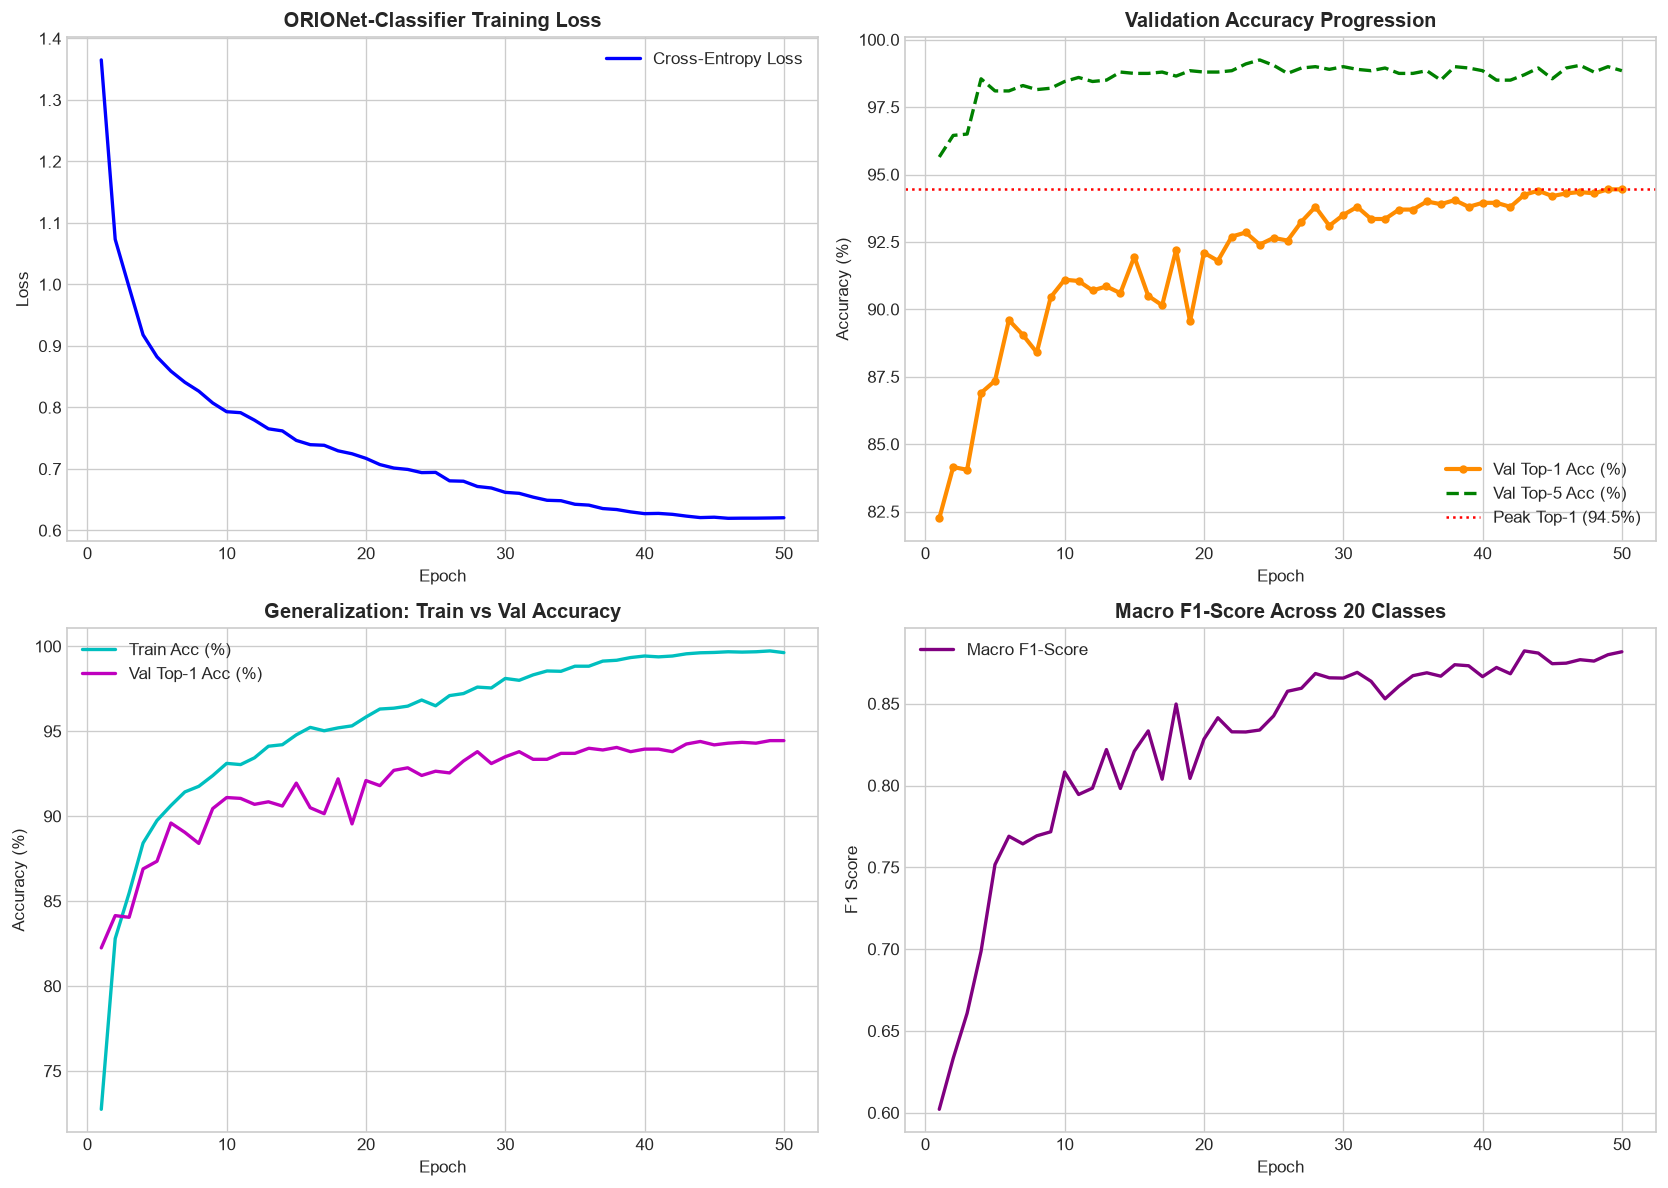


--- ORIONet-Classifier DIOR-R Benchmark Performance Summary ---
              Metric                                  Result
 Best Top-1 Accuracy                                  94.45%
Final Top-5 Accuracy                                  98.85%
      Final Macro F1                                  0.8817
        Total Epochs                                      50
        Architecture ORIONet-Classifier (FOEM+RAFM+SCA+AMSF)


In [8]:
# Cell 8: Quantitative Metric Analysis & Convergence Curves
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axs = plt.subplots(2, 2, figsize=(14, 10), dpi=120)

epochs_range = history['epoch']

# 1. Training Loss Trajectory
axs[0, 0].plot(epochs_range, history['train_loss'], 'b-', lw=2, label='Cross-Entropy Loss')
axs[0, 0].set_title('ORIONet-Classifier Training Loss', fontsize=12, fontweight='bold')
axs[0, 0].set_xlabel('Epoch')
axs[0, 0].set_ylabel('Loss')
axs[0, 0].legend()
axs[0, 0].grid(True)

# 2. Top-1 vs Top-5 Accuracy
axs[0, 1].plot(epochs_range, np.array(history['val_top1']) * 100, 'darkorange', lw=2.5, marker='o', markersize=4, label='Val Top-1 Acc (%)')
axs[0, 1].plot(epochs_range, np.array(history['val_top5']) * 100, 'g--', lw=2, label='Val Top-5 Acc (%)')
axs[0, 1].axhline(y=max(history['val_top1'])*100 if history['val_top1'] else 0, color='r', linestyle=':', label=f'Peak Top-1 ({best_top1*100:.1f}%)')
axs[0, 1].set_title('Validation Accuracy Progression', fontsize=12, fontweight='bold')
axs[0, 1].set_xlabel('Epoch')
axs[0, 1].set_ylabel('Accuracy (%)')
axs[0, 1].legend()
axs[0, 1].grid(True)

# 3. Training vs Validation Accuracy
axs[1, 0].plot(epochs_range, np.array(history['train_acc']) * 100, 'c-', lw=2, label='Train Acc (%)')
axs[1, 0].plot(epochs_range, np.array(history['val_top1']) * 100, 'm-', lw=2, label='Val Top-1 Acc (%)')
axs[1, 0].set_title('Generalization: Train vs Val Accuracy', fontsize=12, fontweight='bold')
axs[1, 0].set_xlabel('Epoch')
axs[1, 0].set_ylabel('Accuracy (%)')
axs[1, 0].legend()
axs[1, 0].grid(True)

# 4. Macro F1-Score
axs[1, 1].plot(epochs_range, history['val_f1'], 'purple', lw=2, label='Macro F1-Score')
axs[1, 1].set_title('Macro F1-Score Across 20 Classes', fontsize=12, fontweight='bold')
axs[1, 1].set_xlabel('Epoch')
axs[1, 1].set_ylabel('F1 Score')
axs[1, 1].legend()
axs[1, 1].grid(True)

plt.tight_layout()
plt.show()

# Performance Summary Table
perf_df = pd.DataFrame({
    'Metric': ['Best Top-1 Accuracy', 'Final Top-5 Accuracy', 'Final Macro F1', 'Total Epochs', 'Architecture'],
    'Result': [f"{best_top1*100:.2f}%", f"{history['val_top5'][-1]*100:.2f}%" if history['val_top5'] else 'N/A',
               f"{history['val_f1'][-1]:.4f}" if history['val_f1'] else 'N/A',
               f"{NUM_EPOCHS}", f"ORIONet-Classifier (FOEM+RAFM+SCA+AMSF)"]
})
print("\n--- ORIONet-Classifier DIOR-R Benchmark Performance Summary ---")
print(perf_df.to_string(index=False))


Generating qualitative classification predictions...


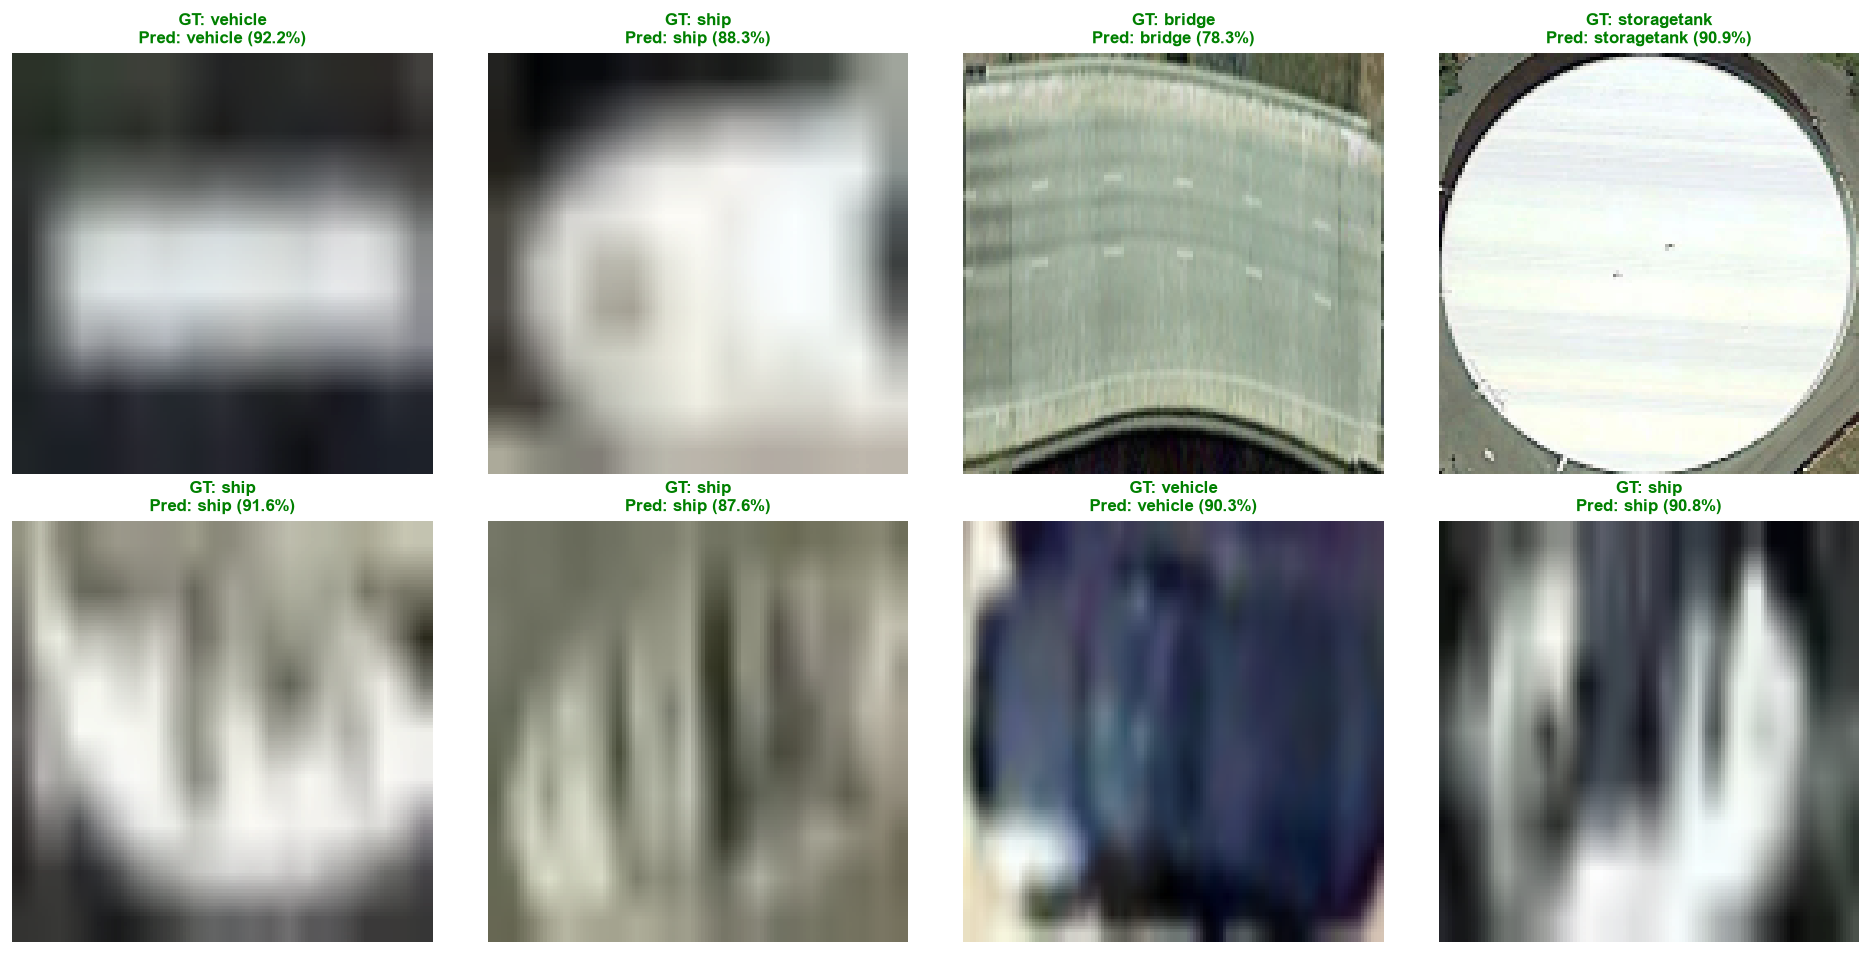

In [9]:
# Cell 9: Qualitative Patch Classification Visualizer
def visualize_patch_classifications(model, dataset, indices=[0, 1, 2, 3, 4, 5, 6, 7]):
    """
    Renders sample cropped aerial object patches with Ground Truth and Predicted class probabilities.
    """
    model.eval()
    cols = 4
    rows = math.ceil(len(indices) / cols)
    fig, axs = plt.subplots(rows, cols, figsize=(16, 4 * rows), dpi=120)
    axs = axs.flatten()
    
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    
    with torch.no_grad():
        for i, idx in enumerate(indices):
            tensor, target = dataset[idx]
            inp = tensor.unsqueeze(0).to(device)
            
            with torch.amp.autocast('cuda' if device.type == 'cuda' else 'cpu'):
                logits = model(inp)
                probs = F.softmax(logits, dim=1)
                conf, pred = torch.max(probs, 1)
                
            pred_cid = pred.item()
            gt_cid = target.item()
            conf_score = conf.item()
            
            # Denormalize patch for display
            img_np = tensor.permute(1, 2, 0).numpy()
            img_np = np.clip(img_np * std + mean, 0.0, 1.0)
            
            is_correct = pred_cid == gt_cid
            title_color = 'green' if is_correct else 'red'
            
            axs[i].imshow(img_np)
            axs[i].set_title(f"GT: {CLASSES[gt_cid]}\nPred: {CLASSES[pred_cid]} ({conf_score*100:.1f}%)",
                             color=title_color, fontsize=10, fontweight='bold')
            axs[i].axis('off')
            
    for j in range(len(indices), len(axs)):
        axs[j].axis('off')
        
    plt.tight_layout()
    plt.show()

print("Generating qualitative classification predictions...")
visualize_patch_classifications(model, val_dataset, indices=list(range(8)))


## 8. Modular Ablation Study Protocol for Research Publication

To substantiate the individual contribution of each proposed module in your conference paper, evaluate the following standardized classification variants:
1. **Baseline CNN**: Multi-stage Inverted Residual Backbone + Linear Head (Without FOEM, RAFM, SCA, AMSF)
2. **Baseline + FOEM**: Evaluates impact of fine-grained object enhancement on small-object classification accuracy.
3. **Baseline + RAFM**: Evaluates rotation-aware directional kernels on rotated patch robustness.
4. **Baseline + SCA**: Evaluates multi-dilation spatial context aggregation on complex aerial targets.
5. **Full ORIONet-Classifier (All Modules + AMSF)**: Evaluates complete unified framework with adaptive multi-scale fusion.


In [10]:
# Cell 10: Modular Ablation Study Configuration Framework
class ConfigurableORIONetClassifier(nn.Module):
    """
    Ablation-ready ORIONet-Classifier supporting dynamic enabling/disabling of:
    - FOEM (use_foem)
    - RAFM (use_rafm)
    - SCA (use_sca)
    - AMSF (use_amsf)
    """
    def __init__(self, num_classes=20, use_foem=True, use_rafm=True, use_sca=True, use_amsf=True):
        super().__init__()
        self.use_foem = use_foem
        self.use_amsf = use_amsf
        
        self.stem = nn.Sequential(
            ConvBNSiLU(3, 32, 3, s=2),
            ConvBNSiLU(32, 64, 3, s=1)
        )
        if self.use_foem:
            self.stage1 = nn.Sequential(InvertedResidual(64, 64), FOEM(64))
        else:
            self.stage1 = InvertedResidual(64, 64)
            
        if use_rafm:
            self.stage2 = nn.Sequential(InvertedResidual(64, 128, stride=2), RAFM(128))
        else:
            self.stage2 = InvertedResidual(64, 128, stride=2)
            
        if use_sca:
            self.stage3 = nn.Sequential(InvertedResidual(128, 256, stride=2), SCA(256))
        else:
            self.stage3 = InvertedResidual(128, 256, stride=2)
            
        self.stage4 = InvertedResidual(256, 512, stride=2)
        
        if self.use_amsf:
            self.amsf = AMSFClassifier([64, 128, 256, 512], out_channels=256)
            head_in = 256
        else:
            self.pool_simple = nn.AdaptiveAvgPool2d(1)
            head_in = 512
            
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.LayerNorm(head_in),
            nn.Dropout(0.2),
            nn.Linear(head_in, num_classes)
        )

    def forward(self, x):
        x = self.stem(x)
        c1 = self.stage1(x)
        c2 = self.stage2(c1)
        c3 = self.stage3(c2)
        c4 = self.stage4(c3)
        
        if self.use_amsf:
            fused = self.amsf([c1, c2, c3, c4])
            out = self.head(F.adaptive_avg_pool2d(fused, 1))
        else:
            out = self.head(self.pool_simple(c4))
        return out

print("Ablation Framework initialized.")
print("To run an ablation experiment: model = ConfigurableORIONetClassifier(use_foem=False, use_rafm=False, ...)")


Ablation Framework initialized.
To run an ablation experiment: model = ConfigurableORIONetClassifier(use_foem=False, use_rafm=False, ...)


In [11]:

# ============================================================
# CELL 1: PER-CLASS CLASSIFICATION METRICS
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

def calculate_per_class_metrics(
    y_true,
    y_pred,
    class_names
):
    """
    Calculate per-class:
      - One-vs-rest accuracy
      - Precision
      - Recall
      - F1-score
      - Support

    Also calculate overall accuracy, macro metrics,
    weighted metrics, and micro metrics.
    """

    y_true = np.asarray(y_true, dtype=np.int64)
    y_pred = np.asarray(y_pred, dtype=np.int64)

    if len(y_true) == 0:
        raise ValueError("No test samples were evaluated.")

    if len(y_true) != len(y_pred):
        raise ValueError("y_true and y_pred lengths differ.")

    if np.any(y_true < 0) or np.any(y_true >= len(class_names)):
        raise ValueError("Ground-truth class IDs are out of range.")

    if np.any(y_pred < 0) or np.any(y_pred >= len(class_names)):
        raise ValueError("Predicted class IDs are out of range.")

    labels = np.arange(len(class_names))

    # Confusion matrix: rows = actual, columns = predicted
    cm = confusion_matrix(
        y_true, y_pred, labels=labels
    )

    # Class-wise precision, recall, F1, and support
    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=labels,
            average=None,
            zero_division=0
        )
    )

    total = len(y_true)
    per_class_accuracy = []

    for c in labels:
        tp = cm[c, c]
        fn = cm[c, :].sum() - tp
        fp = cm[:, c].sum() - tp
        tn = total - tp - fn - fp

        # One-vs-rest accuracy for this class
        acc_c = (tp + tn) / total if total else 0.0
        per_class_accuracy.append(acc_c)

    per_class_df = pd.DataFrame({
        "Class": class_names,
        "Class_ID": labels,
        "Accuracy (%)": np.array(per_class_accuracy) * 100,
        "Precision (%)": precision * 100,
        "Recall (%)": recall * 100,
        "F1-Score (%)": f1 * 100,
        "Support": support
    })

    # Overall single-label classification accuracy
    overall_accuracy = accuracy_score(y_true, y_pred)

    # Macro: equal importance to every class
    # Weighted: each class weighted by its support
    macro_p, macro_r, macro_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0
        )
    )

    weighted_p, weighted_r, weighted_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=labels,
            average="weighted",
            zero_division=0
        )
    )

    micro_p, micro_r, micro_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=labels,
            average="micro",
            zero_division=0
        )
    )

    overall_metrics = {
        "Test Samples": total,
        "Overall Accuracy (%)": overall_accuracy * 100,
        "Macro Precision (%)": macro_p * 100,
        "Macro Recall (%)": macro_r * 100,
        "Macro F1-Score (%)": macro_f1 * 100,
        "Weighted Precision (%)": weighted_p * 100,
        "Weighted Recall (%)": weighted_r * 100,
        "Weighted F1-Score (%)": weighted_f1 * 100,
        "Micro Precision (%)": micro_p * 100,
        "Micro Recall (%)": micro_r * 100,
        "Micro F1-Score (%)": micro_f1 * 100
    }

    return per_class_df, overall_metrics, cm


In [14]:

# ============================================================
# CELL 2: LOAD BEST MODEL AND EVALUATE TEST SET
# ============================================================

import os
import torch
from torch.utils.data import DataLoader

# ----------------------------
# 1. Configuration
# ----------------------------
TEST_SPLIT = "test"
BATCH_SIZE_TEST = 32

TEST_MODEL_PATH = BEST_MODEL_PATH
# Example:
# TEST_MODEL_PATH = "best_orionet_classifier.pth"

if not os.path.isfile(TEST_MODEL_PATH):
    raise FileNotFoundError(
        f"Checkpoint not found: {TEST_MODEL_PATH}\n"
        "Check that the model was saved and that the path is correct."
    )

test_images_dir = os.path.join(
    DATASET_ROOT, TEST_SPLIT, "images"
)
test_labels_dir = os.path.join(
    DATASET_ROOT, TEST_SPLIT, "labels"
)

if not os.path.isdir(test_images_dir):
    raise FileNotFoundError(
        f"Test images directory not found: {test_images_dir}"
    )

if not os.path.isdir(test_labels_dir):
    raise FileNotFoundError(
        f"Test labels directory not found: {test_labels_dir}"
    )

# ----------------------------
# 2. Build test dataset
# ----------------------------
# IMPORTANT:
# max_samples=None indexes the entire split according to the
# existing dataset class. It does not use training augmentation.
test_dataset = DIORRCroppedClassificationDataset(
    root_dir=DATASET_ROOT,
    split=TEST_SPLIT,
    target_size=TARGET_SIZE,
    max_samples=2000,
    augment=False
)

if len(test_dataset) == 0:
    raise RuntimeError(
        "The test dataset contains zero indexed object patches. "
        "Check image/label paths and annotation format."
    )

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE_TEST,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print(f"Test object patches: {len(test_dataset)}")
print(f"Evaluation device: {device}")

# ----------------------------
# 3. Load the trained checkpoint
# ----------------------------
try:
    checkpoint = torch.load(
        TEST_MODEL_PATH,
        map_location=device,
        weights_only=True
    )
except TypeError:
    # Compatibility with PyTorch versions without weights_only
    checkpoint = torch.load(
        TEST_MODEL_PATH,
        map_location=device
    )

if "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    # Also support a checkpoint containing only the state dict
    state_dict = checkpoint

model.load_state_dict(state_dict)
model = model.to(device)
model.eval()

if isinstance(checkpoint, dict) and "epoch" in checkpoint:
    print(f"Loaded checkpoint from epoch: {checkpoint['epoch']}")

if isinstance(checkpoint, dict) and "best_top1" in checkpoint:
    print(
        "Saved best validation accuracy: "
        f"{checkpoint['best_top1'] * 100:.2f}%"
    )

# ----------------------------
# 4. Run inference on test set
# ----------------------------
all_test_targets = []
all_test_predictions = []
all_test_probabilities = []

amp_enabled = (device.type == "cuda")

with torch.inference_mode():
    for images, targets in tqdm(
        test_loader,
        desc="Evaluating ORIONet on test set"
    ):
        images = images.to(device, non_blocking=True)

        with torch.amp.autocast(
            device_type=device.type,
            enabled=amp_enabled
        ):
            logits = model(images)

        probabilities = torch.softmax(logits.float(), dim=1)
        predictions = torch.argmax(probabilities, dim=1)

        all_test_targets.extend(
            targets.cpu().numpy().tolist()
        )
        all_test_predictions.extend(
            predictions.cpu().numpy().tolist()
        )
        all_test_probabilities.extend(
            probabilities.cpu().numpy().tolist()
        )

y_test_true = np.asarray(
    all_test_targets, dtype=np.int64
)
y_test_pred = np.asarray(
    all_test_predictions, dtype=np.int64
)
y_test_probabilities = np.asarray(
    all_test_probabilities, dtype=np.float32
)

assert len(y_test_true) == len(test_dataset)
assert len(y_test_pred) == len(test_dataset)

print("\nTest inference completed.")
print(f"Evaluated samples: {len(y_test_true)}")
print(f"Probability matrix shape: {y_test_probabilities.shape}")


Indexing object annotations for 'test' split...
Indexed 2000 rotated object patches for test split.
Test object patches: 2000
Evaluation device: cuda
Loaded checkpoint from epoch: 49
Saved best validation accuracy: 94.45%


Evaluating ORIONet on test set: 100%|██████████| 63/63 [00:20<00:00,  3.09it/s]


Test inference completed.
Evaluated samples: 2000
Probability matrix shape: (2000, 20)


ORIONet CLASSIFIER — FINAL TEST SET RESULTS
Checkpoint:             best_orionet_classifier.pth
Number of test samples: 2000
Number of classes:      20
Top-1 Accuracy:         94.95%
Top-5 Accuracy:         98.90%
---------------------------------------------------------------------------
MACRO-AVERAGED METRICS
Precision:              87.68%
Recall:                 86.20%
F1-Score:               86.65%
---------------------------------------------------------------------------
WEIGHTED-AVERAGED METRICS
Precision:              95.00%
Recall:                 94.95%
F1-Score:               94.90%
---------------------------------------------------------------------------
MICRO-AVERAGED METRICS
Precision:              94.95%
Recall:                 94.95%
F1-Score:               94.95%

PER-CLASS TEST METRICS


,Class,Class_ID,Accuracy (%),Precision (%),Recall (%),F1-Score (%),Support
0,airplane,0,100.00,100.00,100.00,100.00,57
1,airport,1,99.80,85.71,85.71,85.71,14
2,baseballfield,2,99.95,98.59,100.00,99.29,70
3,basketballcourt,3,99.90,96.15,96.15,96.15,26
4,bridge,4,98.35,48.39,46.88,47.62,32
5,chimney,5,99.80,100.00,78.95,88.24,19
6,dam,6,99.25,66.67,42.11,51.61,19
7,Expressway-Service-area,7,99.90,88.89,100.00,94.12,16
8,Expressway-toll-station,8,99.75,72.73,80.00,76.19,10
9,golffield,9,99.90,88.24,100.00,93.75,15



SCIKIT-LEARN CLASSIFICATION REPORT
                         precision    recall  f1-score   support

               airplane     1.0000    1.0000    1.0000        57
                airport     0.8571    0.8571    0.8571        14
          baseballfield     0.9859    1.0000    0.9929        70
        basketballcourt     0.9615    0.9615    0.9615        26
                 bridge     0.4839    0.4688    0.4762        32
                chimney     1.0000    0.7895    0.8824        19
                    dam     0.6667    0.4211    0.5161        19
Expressway-Service-area     0.8889    1.0000    0.9412        16
Expressway-toll-station     0.7273    0.8000    0.7619        10
              golffield     0.8824    1.0000    0.9375        15
       groundtrackfield     1.0000    0.9286    0.9630        42
                 harbor     0.9452    0.9452    0.9452        73
               overpass     0.4286    0.4839    0.4545        31
                   ship     0.9858    0.9825    0.984

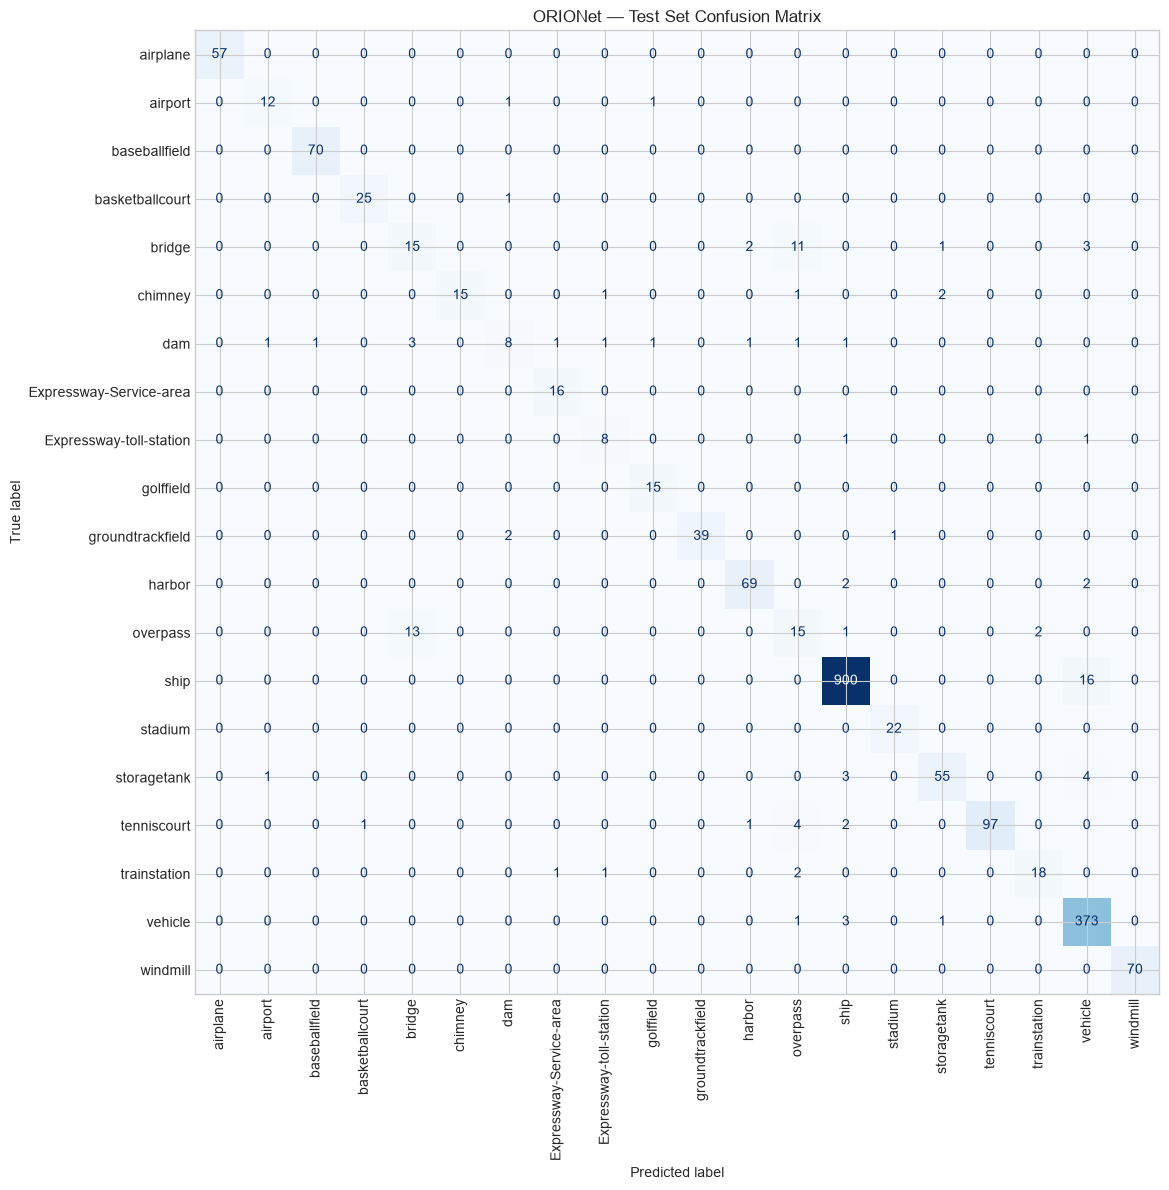


Saved test results:
  Per-class metrics: orionet_test_per_class_metrics.csv
  Overall metrics:   orionet_test_overall_metrics.csv
  Confusion matrix:  orionet_test_confusion_matrix.csv


In [15]:

# ============================================================
# CELL 3: FINAL TEST METRICS AND REPORTS
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# ----------------------------
# 1. Calculate all metrics
# ----------------------------
per_class_df, overall_metrics, test_cm = (
    calculate_per_class_metrics(
        y_true=y_test_true,
        y_pred=y_test_pred,
        class_names=CLASSES
    )
)

# Top-5 accuracy
top5_predictions = np.argsort(
    y_test_probabilities, axis=1
)[:, -min(5, NUM_CLASSES):]

top5_accuracy = np.mean([
    y_test_true[i] in top5_predictions[i]
    for i in range(len(y_test_true))
]) * 100

# ----------------------------
# 2. Print overall metrics
# ----------------------------
print("=" * 75)
print("ORIONet CLASSIFIER — FINAL TEST SET RESULTS")
print("=" * 75)

print(f"Checkpoint:             {TEST_MODEL_PATH}")
print(f"Number of test samples: {len(y_test_true)}")
print(f"Number of classes:      {NUM_CLASSES}")
print(f"Top-1 Accuracy:         {overall_metrics['Overall Accuracy (%)']:.2f}%")
print(f"Top-5 Accuracy:         {top5_accuracy:.2f}%")
print("-" * 75)

print("MACRO-AVERAGED METRICS")
print(f"Precision:              {overall_metrics['Macro Precision (%)']:.2f}%")
print(f"Recall:                 {overall_metrics['Macro Recall (%)']:.2f}%")
print(f"F1-Score:               {overall_metrics['Macro F1-Score (%)']:.2f}%")
print("-" * 75)

print("WEIGHTED-AVERAGED METRICS")
print(f"Precision:              {overall_metrics['Weighted Precision (%)']:.2f}%")
print(f"Recall:                 {overall_metrics['Weighted Recall (%)']:.2f}%")
print(f"F1-Score:               {overall_metrics['Weighted F1-Score (%)']:.2f}%")
print("-" * 75)

print("MICRO-AVERAGED METRICS")
print(f"Precision:              {overall_metrics['Micro Precision (%)']:.2f}%")
print(f"Recall:                 {overall_metrics['Micro Recall (%)']:.2f}%")
print(f"F1-Score:               {overall_metrics['Micro F1-Score (%)']:.2f}%")
print("=" * 75)

# ----------------------------
# 3. Per-class metric table
# ----------------------------
print("\nPER-CLASS TEST METRICS")
display(
    per_class_df.style.format({
        "Accuracy (%)": "{:.2f}",
        "Precision (%)": "{:.2f}",
        "Recall (%)": "{:.2f}",
        "F1-Score (%)": "{:.2f}"
    })
)

# ----------------------------
# 4. Complete classification report
# ----------------------------
print("\nSCIKIT-LEARN CLASSIFICATION REPORT")
print(
    classification_report(
        y_test_true,
        y_test_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASSES,
        digits=4,
        zero_division=0
    )
)

# ----------------------------
# 5. Plot confusion matrix
# ----------------------------
fig, ax = plt.subplots(figsize=(14, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=CLASSES
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False,
    values_format="d"
)

ax.set_title("ORIONet — Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

# ----------------------------
# 6. Save results
# ----------------------------
PER_CLASS_CSV = "orionet_test_per_class_metrics.csv"
OVERALL_CSV = "orionet_test_overall_metrics.csv"
CONFUSION_MATRIX_CSV = "orionet_test_confusion_matrix.csv"

per_class_df.to_csv(PER_CLASS_CSV, index=False)

overall_df = pd.DataFrame(
    list(overall_metrics.items()),
    columns=["Metric", "Value"]
)

overall_df = pd.concat([
    overall_df,
    pd.DataFrame([{
        "Metric": "Top-5 Accuracy (%)",
        "Value": top5_accuracy
    }])
], ignore_index=True)

overall_df.to_csv(OVERALL_CSV, index=False)

cm_df = pd.DataFrame(
    test_cm,
    index=[f"Actual_{c}" for c in CLASSES],
    columns=[f"Predicted_{c}" for c in CLASSES]
)
cm_df.to_csv(CONFUSION_MATRIX_CSV)

print("\nSaved test results:")
print(f"  Per-class metrics: {PER_CLASS_CSV}")
print(f"  Overall metrics:   {OVERALL_CSV}")
print(f"  Confusion matrix:  {CONFUSION_MATRIX_CSV}")


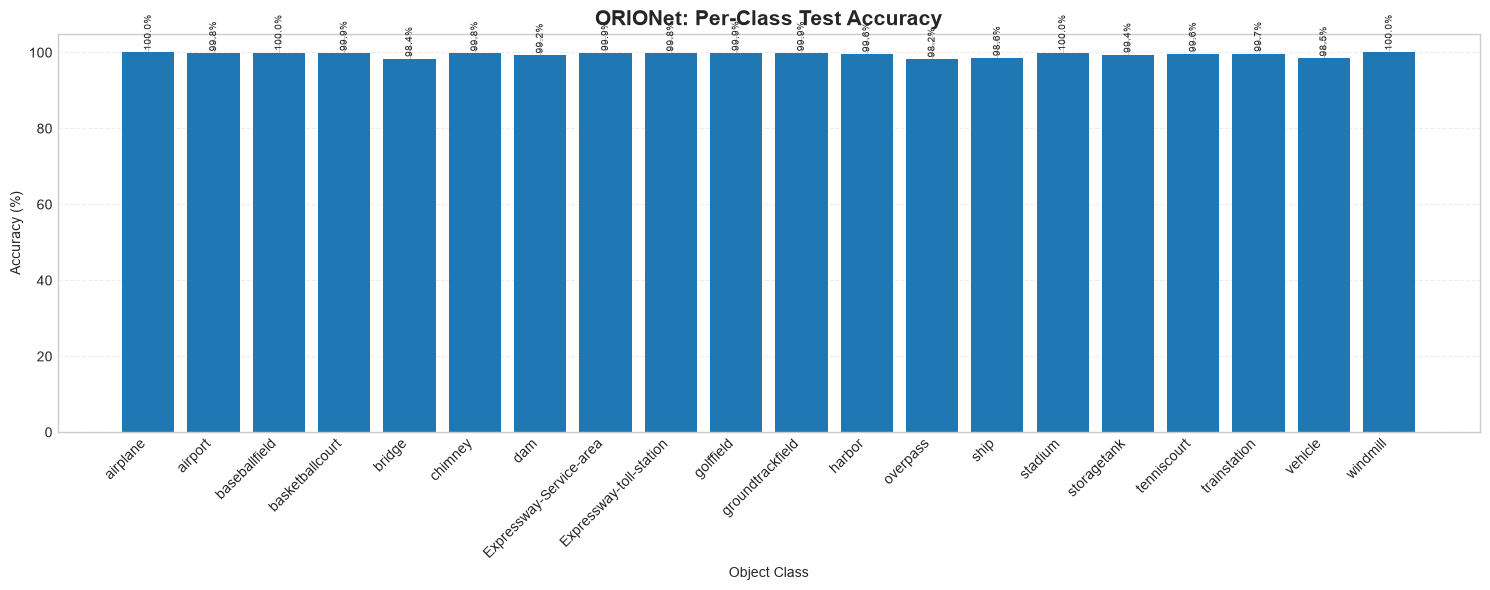

In [20]:
import matplotlib.pyplot as plt
import numpy as np

classes = per_class_df["Class"].astype(str).tolist()
accuracy = per_class_df["Accuracy (%)"].to_numpy()

plt.figure(figsize=(15, 6))
bars = plt.bar(classes, accuracy)

plt.title("ORIONet: Per-Class Test Accuracy", fontsize=15, fontweight="bold")
plt.xlabel("Object Class")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.35)

for bar, value in zip(bars, accuracy):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=7,
        rotation=90
    )

plt.tight_layout()
plt.savefig("ORIONet_test_per_class_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

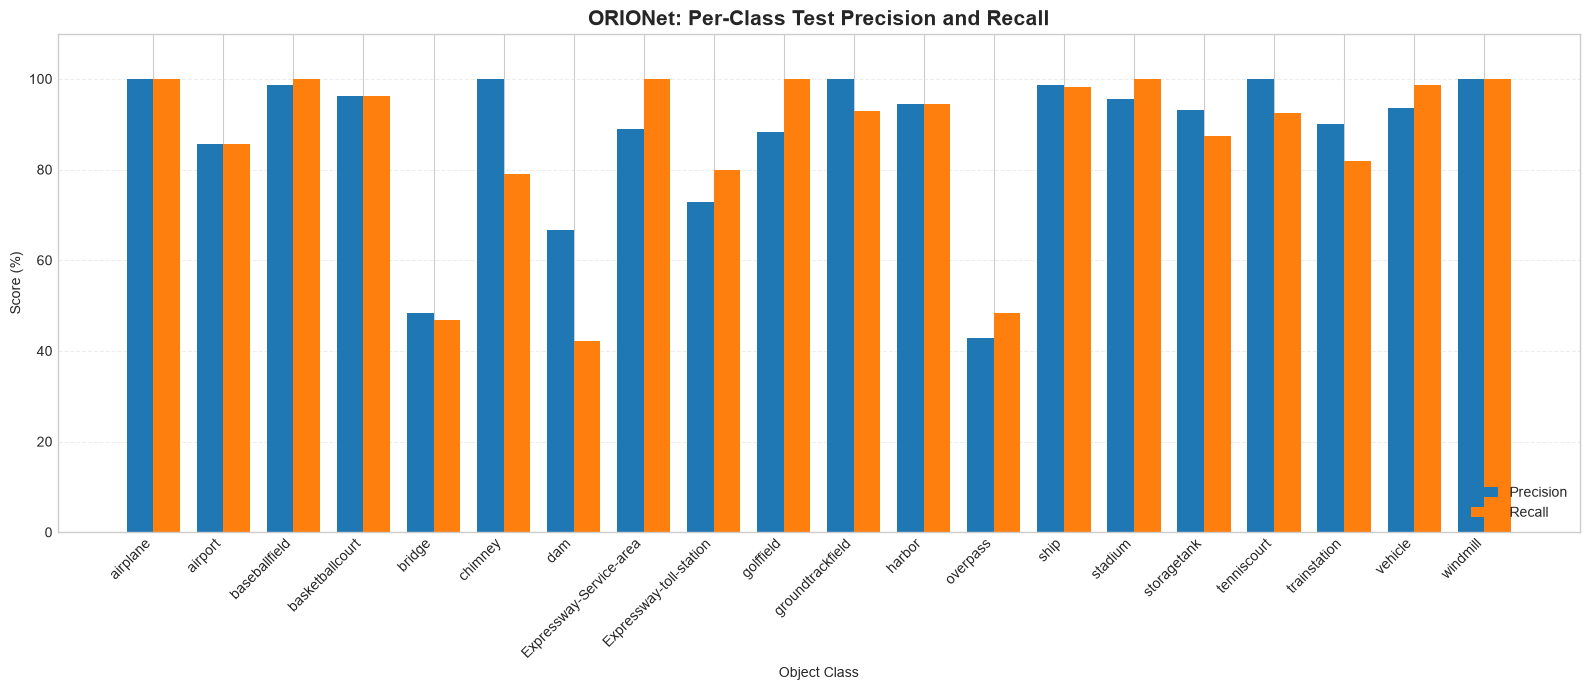

In [21]:
x = np.arange(len(classes))
width = 0.38

precision = per_class_df["Precision (%)"].to_numpy()
recall = per_class_df["Recall (%)"].to_numpy()

plt.figure(figsize=(16, 7))

plt.bar(x - width / 2, precision, width, label="Precision")
plt.bar(x + width / 2, recall, width, label="Recall")

plt.title(
    "ORIONet: Per-Class Test Precision and Recall",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Object Class")
plt.ylabel("Score (%)")
plt.ylim(0, 110)
plt.xticks(x, classes, rotation=45, ha="right")
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.savefig("ORIONet_test_precision_recall.png", dpi=300, bbox_inches="tight")
plt.show()


In [23]:

# ============================================================
# ROTATION ROBUSTNESS EVALUATION — ORIONet
# No retraining. Same test samples at every rotation angle.
# ============================================================

import numpy as np
import pandas as pd
import torch
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode
from sklearn.metrics import accuracy_score, f1_score

model.eval()

ROTATION_ANGLES = [0, 90, 180, 270]
rotation_results = []

amp_enabled = device.type == "cuda"

for angle in ROTATION_ANGLES:
    targets_all = []
    predictions_all = []

    with torch.inference_mode():
        for images, targets in test_loader:
            images = images.to(device, non_blocking=True)
            targets = targets.to(device)

            # Rotate normalized tensor patches.
            # Fill=0 represents the normalized mean color.
            if angle != 0:
                images = TF.rotate(
                    images,
                    angle=angle,
                    interpolation=InterpolationMode.BILINEAR,
                    expand=False,
                    fill=0
                )

            with torch.amp.autocast(
                device_type=device.type,
                enabled=amp_enabled
            ):
                logits = model(images)

            predictions = logits.argmax(dim=1)

            targets_all.extend(targets.cpu().tolist())
            predictions_all.extend(predictions.cpu().tolist())

    y_true = np.asarray(targets_all)
    y_pred = np.asarray(predictions_all)

    rotation_results.append({
        "Rotation (degrees)": angle,
        "Samples": len(y_true),
        "Top-1 accuracy (%)": 100 * accuracy_score(
            y_true, y_pred
        ),
        "Macro F1 (%)": 100 * f1_score(
            y_true, y_pred,
            labels=np.arange(NUM_CLASSES),
            average="macro",
            zero_division=0
        )
    })

rotation_df = pd.DataFrame(rotation_results)

# Calculate drops relative to the unrotated condition.
baseline_acc = rotation_df.loc[
    rotation_df["Rotation (degrees)"] == 0,
    "Top-1 accuracy (%)"
].iloc[0]

baseline_f1 = rotation_df.loc[
    rotation_df["Rotation (degrees)"] == 0,
    "Macro F1 (%)"
].iloc[0]

rotation_df["Accuracy drop (percentage points)"] = (
    baseline_acc - rotation_df["Top-1 accuracy (%)"]
)

rotation_df["Macro F1 drop (percentage points)"] = (
    baseline_f1 - rotation_df["Macro F1 (%)"]
)

print("ORIONet ROTATION ROBUSTNESS RESULTS")
display(rotation_df.round(3))

print(
    "\nNote: drops are measured relative to the 0-degree "
    "condition; negative values indicate an improvement."
)


ORIONet ROTATION ROBUSTNESS RESULTS


,Rotation (degrees),Samples,Top-1 accuracy (%),Macro F1 (%),Accuracy drop (percentage points),Macro F1 drop (percentage points)
0,0,2000,94.95,86.654,0.00,0.000
1,90,2000,95.00,87.851,-0.05,-1.197
2,180,2000,95.05,86.806,-0.10,-0.152
3,270,2000,94.90,87.784,0.05,-1.131



Note: drops are measured relative to the 0-degree condition; negative values indicate an improvement.
